# LightGCN: Simplifying and Powering Graph Convolution Network for Recommendation

**Paper**: *LightGCN: Simplifying and Powering Graph Convolution Network for Recommendation* (Xiangnan He, Kuan Deng, Xiang Wang, Yan Li, YongDong Zhang, and Meng Wang, SIGIR 2020)  
**Official Model Reference**: [gusye1234/LightGCN-PyTorch](https://github.com/gusye1234/LightGCN-PyTorch) (`code/model.py`)  
**Preprocess & Evaluation Pipeline**: Shared with [SGL_Colab.ipynb](file:///c:/Users/Dell/Documents/Kornrawee/university/Year4_1/rec_sys/SGL-implementation/SGL_Colab.ipynb) for direct, apples-to-apples comparison.

This self-contained Google Colab notebook merges the entire pipeline into a single file:
1. **Environment & Reproducibility Setup**: Imports, device detection (`CUDA` / `CPU`), and seed fixing.
2. **Dataset Download / Generation & Preprocessing (Shared Pipeline)**:
   - Automatically downloads official benchmark datasets (`yelp2018`, `amazon-book`, `ifashion`) or generates the identical synthetic power-law dataset.
   - Builds the symmetrically normalized bipartite interaction graph $\tilde{A} = D^{-1/2} A D^{-1/2}$.
   - Uses the exact same `PairwiseSampler` for BPR training triplets $\mathcal{O} = \{(u, i, j) \mid (u, i) \in \mathcal{O}^+, (u, j) \in \mathcal{O}^-\}$.
3. **LightGCN Model (`LightGCN` from `gusye1234/LightGCN-PyTorch`)**:
   - `__init_weight`: Initializes 0-th layer ego embeddings `embedding_user` and `embedding_item` (supports $\mathcal{N}(0, 0.1^2)$ normal initialization from `LightGCN-PyTorch` or `xavier_uniform`).
   - `__dropout_x` & `__dropout`: Optional sparse adjacency matrix edge dropout with inverted rescaling (`values / keep_prob`).
   - `computer()`: Performs $L$-layer LightGCN propagation $E^{(k+1)} = \tilde{A} E^{(k)}$ and uniform mean layer readout $E = \frac{1}{L+1}\sum_{k=0}^L E^{(k)}$.
   - `getUsersRating()`, `getEmbedding()`, and `bpr_loss()`: Computes the BPR ranking loss $\text{softplus}(\hat{y}_{uj} - \hat{y}_{ui})$ and $L_2$ regularization on 0-th layer ego embeddings.
4. **All-Ranking Top-$K$ Evaluation & Long-Tail Analysis (`Evaluator` — Shared Pipeline)**:
   - Full-ranking `Precision@K`, `Recall@K`, and `NDCG@K` ($K = 20$) with training interaction masking.
   - Long-tail item popularity group decomposition (`Recall@20` across 10 item degree groups).
5. **End-to-End Training Loop & Visualization**:
   - Trains `LightGCN`, tracks early stopping, and plots training loss curves, Top-$K$ test metrics, and Long-Tail Group Recall.

In [1]:
# ==============================================================================
# 1. Environment Setup & Imports (Colab Ready)
# ==============================================================================
import os
import random
import urllib.request
from collections import defaultdict
from dataclasses import dataclass, field
from time import time

import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sp
import torch
import torch.nn as nn
import torch.nn.functional as F


def set_seed(seed: int = 2021) -> None:
    """Fixes random seeds across Python, NumPy, and PyTorch (CPU & CUDA) for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True


DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"PyTorch Version: {torch.__version__} | Running on Device: {DEVICE}")

PyTorch Version: 2.11.0+cu130 | Running on Device: cuda:0


## 2. Data Preprocessing, Bipartite Graph Construction & BPR Sampler (Shared Pipeline)

This section uses the **exact same data preprocessing and sampling pipeline** as `SGL_Colab.ipynb`:
- Loads `<dataset>.train` and `<dataset>.test` (or downloads/generates the dataset automatically).
- Builds the symmetrically normalized bipartite adjacency matrix:
  $$A = \begin{pmatrix} 0 & R \\ R^\top & 0 \end{pmatrix}, \quad \tilde{A} = D^{-1/2} A D^{-1/2}$$
- Provides `getSparseGraph()` on `SGLDataset` (alongside `n_users` and `m_items` properties) so the `LightGCN` class from `gusye1234/LightGCN-PyTorch` plugs into `SGLDataset` seamlessly.

In [2]:
# ==============================================================================
# 2. Data Loading, Preprocessing, Normalized Graph & Pairwise BPR Sampler
# ==============================================================================

def download_sgl_dataset(data_dir: str, dataset_name: str) -> bool:
    """
    Downloads official benchmark dataset files (<dataset>.train and <dataset>.test)
    directly from https://github.com/wujcan/SGL-Torch if requested in Google Colab.
    Supported official datasets: 'yelp2018', 'amazon-book', 'ifashion'.
    """
    if dataset_name not in ["yelp2018", "amazon-book", "ifashion"]:
        return False

    os.makedirs(data_dir, exist_ok=True)
    base_url = f"https://raw.githubusercontent.com/wujcan/SGL-Torch/master/dataset/{dataset_name}"
    for ext in ["train", "test"]:
        target_path = os.path.join(data_dir, f"{dataset_name}.{ext}")
        if not os.path.exists(target_path):
            url = f"{base_url}/{dataset_name}.{ext}"
            print(f"[Download] Fetching {url} ...")
            try:
                urllib.request.urlretrieve(url, target_path)
            except Exception as e:
                print(f"[Download] Could not fetch {url}: {e}")
                return False
    return True


def generate_synthetic_dataset(
    data_dir: str,
    dataset_name: str = "synthetic",
    num_users: int = 300,
    num_items: int = 500,
    interactions_per_user: int = 25,
    seed: int = 2021,
) -> None:
    """
    Generates a synthetic implicit-feedback dataset with a power-law item popularity
    distribution and saves `<dataset_name>.train` and `<dataset_name>.test`.
    """
    os.makedirs(data_dir, exist_ok=True)
    rng = np.random.default_rng(seed)

    item_ranks = np.arange(1, num_items + 1, dtype=np.float64)
    item_probs = item_ranks ** (-0.8)
    item_probs /= item_probs.sum()

    train_pairs, test_pairs = [], []

    for u in range(num_users):
        n_inter = max(5, int(rng.poisson(interactions_per_user)))
        n_inter = min(n_inter, num_items // 2)
        items = rng.choice(num_items, size=n_inter, replace=False, p=item_probs)

        # Split 80% train, 20% test
        n_test = max(1, int(len(items) * 0.2))
        train_items = np.sort(items[:-n_test])
        test_items = np.sort(items[-n_test:])

        for i in train_items:
            train_pairs.append(f"{u},{int(i)}")
        for i in test_items:
            test_pairs.append(f"{u},{int(i)}")

    with open(os.path.join(data_dir, f"{dataset_name}.train"), "w", encoding="utf-8") as f:
        f.write("\n".join(train_pairs) + "\n")

    with open(os.path.join(data_dir, f"{dataset_name}.test"), "w", encoding="utf-8") as f:
        f.write("\n".join(test_pairs) + "\n")


def sp_mat_to_sp_tensor(sp_mat: sp.spmatrix) -> torch.Tensor:
    """Converts a SciPy sparse matrix into a coalesced PyTorch sparse COO tensor."""
    coo = sp_mat.tocoo().astype(np.float32)
    indices = torch.from_numpy(np.asarray([coo.row, coo.col], dtype=np.int64))
    values = torch.from_numpy(coo.data)
    return torch.sparse_coo_tensor(indices, values, coo.shape).coalesce()


class SGLDataset:
    """
    Shared Dataset loader and normalized bipartite graph builder.
    Also exposes `n_users`, `m_items`, and `getSparseGraph()` to match `BasicDataset`
    in `gusye1234/LightGCN-PyTorch`.
    """

    def __init__(
        self,
        data_dir: str = "./dataset/synthetic",
        dataset_name: str = "synthetic",
        device: torch.device = DEVICE,
    ):
        self.data_dir = data_dir
        self.dataset_name = dataset_name
        self.device = device

        train_path, test_path = self._resolve_data_paths()

        self.train_user_dict = defaultdict(list)
        self.test_user_dict = defaultdict(list)
        self.train_user_set = defaultdict(set)

        self.train_users = []
        self.train_items = []

        self.num_users = 0
        self.num_items = 0

        # Parse training and testing interactions
        self._load_file(train_path, is_train=True)
        self._load_file(test_path, is_train=False)

        self.train_users = np.asarray(self.train_users, dtype=np.int32)
        self.train_items = np.asarray(self.train_items, dtype=np.int32)
        self.num_ratings = len(self.train_users)

        self.train_user_dict = {
            u: np.asarray(items, dtype=np.int32) for u, items in self.train_user_dict.items()
        }
        self.test_user_dict = {
            u: np.asarray(items, dtype=np.int32) for u, items in self.test_user_dict.items()
        }

        # Build the intact normalized adjacency matrix D^{-1/2} A D^{-1/2}
        adj_matrix = self.create_adj_mat()
        self.norm_adj = sp_mat_to_sp_tensor(adj_matrix).to(self.device)

    @property
    def n_users(self) -> int:
        """Alias matching `dataset.n_users` in `gusye1234/LightGCN-PyTorch`."""
        return self.num_users

    @property
    def m_items(self) -> int:
        """Alias matching `dataset.m_items` in `gusye1234/LightGCN-PyTorch`."""
        return self.num_items

    def getSparseGraph(self) -> torch.Tensor:
        """Returns the normalized sparse bipartite graph D^{-1/2} A D^{-1/2} on `self.device`."""
        return self.norm_adj

    def _resolve_data_paths(self) -> tuple[str, str]:
        """Checks for existing `.train`/`.test` or `train.txt`/`test.txt`, downloads, or generates synthetic data."""
        sgl_train = os.path.join(self.data_dir, f"{self.dataset_name}.train")
        sgl_test = os.path.join(self.data_dir, f"{self.dataset_name}.test")
        txt_train = os.path.join(self.data_dir, "train.txt")
        txt_test = os.path.join(self.data_dir, "test.txt")

        if os.path.exists(sgl_train) and os.path.exists(sgl_test):
            return sgl_train, sgl_test
        if os.path.exists(txt_train) and os.path.exists(txt_test):
            return txt_train, txt_test

        if download_sgl_dataset(self.data_dir, self.dataset_name):
            return sgl_train, sgl_test

        print(f"[Preprocess] Generating synthetic dataset at '{self.data_dir}'...")
        generate_synthetic_dataset(self.data_dir, self.dataset_name)
        return sgl_train, sgl_test

    def _load_file(self, file_path: str, is_train: bool) -> None:
        """Reads interaction data supporting both CSV (`u,i`) and adjacency-list (`u i1 i2 ...`) formats."""
        with open(file_path, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                parts = line.split(",") if "," in line else line.split()
                if len(parts) < 2:
                    continue

                u = int(parts[0])
                items = [int(x) for x in parts[1:]]

                self.num_users = max(self.num_users, u + 1)
                self.num_items = max(self.num_items, max(items) + 1)

                for i in items:
                    if is_train:
                        if i not in self.train_user_set[u]:
                            self.train_user_dict[u].append(i)
                            self.train_user_set[u].add(i)
                            self.train_users.append(u)
                            self.train_items.append(i)
                    else:
                        self.test_user_dict[u].append(i)

    def create_adj_mat(self) -> sp.spmatrix:
        """
        Builds and normalizes the bipartite user-item adjacency matrix:
            A_hat = D^{-1/2} A D^{-1/2}
        """
        n_nodes = self.num_users + self.num_items
        users_np, items_np = self.train_users, self.train_items

        ratings = np.ones_like(users_np, dtype=np.float32)
        tmp_adj = sp.csr_matrix(
            (ratings, (users_np, items_np + self.num_users)),
            shape=(n_nodes, n_nodes),
        )
        adj_mat = tmp_adj + tmp_adj.T

        # Symmetric Laplacian normalization: D^{-1/2} A D^{-1/2}
        rowsum = np.array(adj_mat.sum(1))
        with np.errstate(divide="ignore"):
            d_inv = np.power(rowsum, -0.5).flatten()
        d_inv[np.isinf(d_inv)] = 0.0
        d_mat_inv = sp.diags(d_inv)
        norm_adj_tmp = d_mat_inv.dot(adj_mat)
        adj_matrix = norm_adj_tmp.dot(d_mat_inv)

        return adj_matrix


class PairwiseSampler:
    """
    Pairwise BPR negative sampler (shared with SGL_Colab.ipynb).
    Uniformly samples training triplets (u, i, j) where (u, i) in O^+ and (u, j) in O^-.
    """

    def __init__(self, dataset: SGLDataset, batch_size: int = 2048, shuffle: bool = True):
        self.dataset = dataset
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.user_pos_dict = dataset.train_user_dict
        self.user_pos_set = dataset.train_user_set
        self.num_trainings = dataset.num_ratings
        self.num_items = dataset.num_items
        self.users = list(self.user_pos_dict.keys())

    def __iter__(self):
        sampled_users = np.random.choice(self.users, size=self.num_trainings, replace=True)
        unique_users, user_counts = np.unique(sampled_users, return_counts=True)

        all_users, all_pos_items, all_neg_items = [], [], []

        for u, count in zip(unique_users, user_counts):
            pos_items_u = self.user_pos_dict[u]
            pos_set_u = self.user_pos_set[u]

            pos_sampled = np.random.choice(pos_items_u, size=count, replace=True)
            neg_sampled = np.empty(count, dtype=np.int32)
            for idx in range(count):
                j = np.random.randint(0, self.num_items)
                while j in pos_set_u:
                    j = np.random.randint(0, self.num_items)
                neg_sampled[idx] = j

            all_users.append(np.full(count, u, dtype=np.int32))
            all_pos_items.append(pos_sampled)
            all_neg_items.append(neg_sampled)

        users_arr = np.concatenate(all_users)
        pos_arr = np.concatenate(all_pos_items)
        neg_arr = np.concatenate(all_neg_items)

        if self.shuffle:
            perm = np.random.permutation(self.num_trainings)
            users_arr = users_arr[perm]
            pos_arr = pos_arr[perm]
            neg_arr = neg_arr[perm]

        for start in range(0, self.num_trainings, self.batch_size):
            end = min(start + self.batch_size, self.num_trainings)
            yield users_arr[start:end], pos_arr[start:end], neg_arr[start:end]

## 3. LightGCN Model Architecture (`gusye1234/LightGCN-PyTorch`)

Below is the PyTorch implementation of **LightGCN** from [`gusye1234/LightGCN-PyTorch/code/model.py`](https://github.com/gusye1234/LightGCN-PyTorch/blob/master/code/model.py):
1. **Weight Initialization (`__init_weight`)**:
   - Creates `self.embedding_user` and `self.embedding_item`.
   - Initializes weights with $\mathcal{N}(0, 0.1^2)$ (`nn.init.normal_(..., std=0.1)`) by default, or `xavier_uniform_` if specified.
2. **Sparse Edge Dropout (`__dropout_x` & `__dropout`)**:
   - When `dropout=1` during training, randomly retains `keep_prob` fraction of non-zero entries in `self.Graph` and rescales kept values by `1 / keep_prob`.
3. **Light Graph Convolution (`computer()`)**:
   - Concatenates user and item 0-th layer embeddings $E^{(0)} = [E_U^{(0)}; E_I^{(0)}]$.
   - Propagates $E^{(k+1)} = \tilde{A} E^{(k)}$ for `n_layers` layers using `torch.sparse.mm`.
   - Combines all layers via uniform average (`torch.mean(torch.stack(embs, dim=1), dim=1)`).
4. **BPR Loss & $L_2$ Regularization (`getEmbedding` & `bpr_loss`)**:
   - Computes pairwise BPR loss using `torch.nn.functional.softplus(neg_scores - pos_scores)`.
   - Computes $L_2$ regularization on the 0-th layer ego embeddings (`userEmb0`, `posEmb0`, `negEmb0`).

In [3]:
# ==============================================================================
# 3. LightGCN Model Implementation (from gusye1234/LightGCN-PyTorch/code/model.py)
# ==============================================================================

class BasicModel(nn.Module):
    def __init__(self):
        super().__init__()

    def getUsersRating(self, users: torch.Tensor) -> torch.Tensor:
        raise NotImplementedError


class LightGCN(BasicModel):
    """
    PyTorch implementation of LightGCN (He et al., SIGIR 2020) from:
    https://github.com/gusye1234/LightGCN-PyTorch/blob/master/code/model.py

    Also includes `predict(users)` and cached eval embeddings so it works directly
    with the shared `Evaluator` from `SGL_Colab.ipynb`.
    """

    def __init__(self, config: dict, dataset: SGLDataset):
        super().__init__()
        self.config = config
        self.dataset = dataset
        self._user_embeddings_final = None
        self._item_embeddings_final = None
        self.__init_weight()

    def __init_weight(self) -> None:
        self.num_users = self.dataset.n_users
        self.num_items = self.dataset.m_items
        self.latent_dim = self.config["latent_dim_rec"]
        self.n_layers = self.config["lightGCN_n_layers"]
        self.keep_prob = self.config.get("keep_prob", 1.0)
        self.A_split = self.config.get("A_split", False)

        # 0-th layer ego ID embeddings
        self.embedding_user = torch.nn.Embedding(
            num_embeddings=self.num_users, embedding_dim=self.latent_dim
        )
        self.embedding_item = torch.nn.Embedding(
            num_embeddings=self.num_items, embedding_dim=self.latent_dim
        )

        if self.config.get("pretrain", 0) == 0:
            init_method = self.config.get("param_init", "normal")
            if init_method == "xavier_uniform":
                nn.init.xavier_uniform_(self.embedding_user.weight, gain=1)
                nn.init.xavier_uniform_(self.embedding_item.weight, gain=1)
                print("[LightGCN] Initialized embeddings with Xavier Uniform.")
            else:
                # Default in gusye1234/LightGCN-PyTorch: Normal N(0, 0.1^2)
                nn.init.normal_(self.embedding_user.weight, std=0.1)
                nn.init.normal_(self.embedding_item.weight, std=0.1)
                print("[LightGCN] Initialized embeddings with Normal(0, 0.1).")
        else:
            self.embedding_user.weight.data.copy_(torch.from_numpy(self.config["user_emb"]))
            self.embedding_item.weight.data.copy_(torch.from_numpy(self.config["item_emb"]))
            print("[LightGCN] Loaded pretrained embeddings.")

        self.f = nn.Sigmoid()
        self.Graph = self.dataset.getSparseGraph()
        print(f"[LightGCN] Ready (n_layers={self.n_layers}, dropout={self.config.get('dropout', 0)}).")

    def __dropout_x(self, x: torch.Tensor, keep_prob: float) -> torch.Tensor:
        """
        Drops edges from sparse tensor `x` with keep probability `keep_prob`
        and rescales surviving edge weights by `1 / keep_prob`.
        """
        x = x.coalesce()
        size = x.size()
        index = x.indices().t()
        values = x.values()
        random_index = torch.rand(len(values), device=values.device) + keep_prob
        random_index = random_index.int().bool()
        index = index[random_index]
        values = values[random_index] / keep_prob
        g = torch.sparse_coo_tensor(index.t(), values, size, device=values.device).coalesce()
        return g

    def __dropout(self, keep_prob: float) -> torch.Tensor | list[torch.Tensor]:
        if self.A_split:
            graph = []
            for g in self.Graph:
                graph.append(self.__dropout_x(g, keep_prob))
        else:
            graph = self.__dropout_x(self.Graph, keep_prob)
        return graph

    def computer(self) -> tuple[torch.Tensor, torch.Tensor]:
        """
        Propagates user and item embeddings across `self.n_layers` LightGCN layers:
            E^{(k+1)} = D^{-1/2} A D^{-1/2} E^{(k)}
            E = (1 / (K + 1)) * sum_{k=0}^{K} E^{(k)}
        """
        users_emb = self.embedding_user.weight
        items_emb = self.embedding_item.weight
        all_emb = torch.cat([users_emb, items_emb])
        embs = [all_emb]

        if self.config.get("dropout", 0) and self.training:
            g_droped = self.__dropout(self.keep_prob)
        else:
            g_droped = self.Graph

        for _ in range(self.n_layers):
            if self.A_split:
                temp_emb = []
                for f in range(len(g_droped)):
                    temp_emb.append(torch.sparse.mm(g_droped[f], all_emb))
                side_emb = torch.cat(temp_emb, dim=0)
                all_emb = side_emb
            else:
                all_emb = torch.sparse.mm(g_droped, all_emb)
            embs.append(all_emb)

        embs = torch.stack(embs, dim=1)
        light_out = torch.mean(embs, dim=1)
        users, items = torch.split(light_out, [self.num_users, self.num_items])
        return users, items

    def getUsersRating(self, users: torch.Tensor) -> torch.Tensor:
        """Computes user-item rating scores across all items using `computer()`."""
        all_users, all_items = self.computer()
        users_emb = all_users[users.long()]
        items_emb = all_items
        rating = self.f(torch.matmul(users_emb, items_emb.t()))
        return rating

    def getEmbedding(
        self, users: torch.Tensor, pos_items: torch.Tensor, neg_items: torch.Tensor
    ) -> tuple[torch.Tensor, ...]:
        """
        Returns both final multi-layer propagated embeddings and 0-th layer ego embeddings
        for the given batch of (users, pos_items, neg_items).
        """
        all_users, all_items = self.computer()
        users_emb = all_users[users]
        pos_emb = all_items[pos_items]
        neg_emb = all_items[neg_items]

        users_emb_ego = self.embedding_user(users)
        pos_emb_ego = self.embedding_item(pos_items)
        neg_emb_ego = self.embedding_item(neg_items)
        return users_emb, pos_emb, neg_emb, users_emb_ego, pos_emb_ego, neg_emb_ego

    def bpr_loss(
        self, users: torch.Tensor, pos: torch.Tensor, neg: torch.Tensor
    ) -> tuple[torch.Tensor, torch.Tensor]:
        """
        Computes the pairwise Bayesian Personalized Ranking (BPR) loss and L2 regularization
        loss exactly as in `gusye1234/LightGCN-PyTorch/code/model.py`:
            loss     = mean(softplus(neg_scores - pos_scores))
            reg_loss = (1/2) * (||u^{(0)}||_2^2 + ||i^{(0)}||_2^2 + ||j^{(0)}||_2^2) / |B|
        """
        users_emb, pos_emb, neg_emb, userEmb0, posEmb0, negEmb0 = self.getEmbedding(
            users.long(), pos.long(), neg.long()
        )
        reg_loss = (
            0.5
            * (userEmb0.norm(2).pow(2) + posEmb0.norm(2).pow(2) + negEmb0.norm(2).pow(2))
            / float(len(users))
        )

        pos_scores = torch.mul(users_emb, pos_emb)
        pos_scores = torch.sum(pos_scores, dim=1)
        neg_scores = torch.mul(users_emb, neg_emb)
        neg_scores = torch.sum(neg_scores, dim=1)

        loss = torch.mean(torch.nn.functional.softplus(neg_scores - pos_scores))
        return loss, reg_loss

    def forward(self, users: torch.Tensor, items: torch.Tensor) -> torch.Tensor:
        all_users, all_items = self.computer()
        users_emb = all_users[users]
        items_emb = all_items[items]
        inner_pro = torch.mul(users_emb, items_emb)
        gamma = torch.sum(inner_pro, dim=1)
        return gamma

    def eval(self):
        """Precomputes and caches `computer()` embeddings when switching to eval mode."""
        super().eval()
        with torch.no_grad():
            self._user_embeddings_final, self._item_embeddings_final = self.computer()
        return self

    @torch.no_grad()
    def predict(self, users: np.ndarray | list[int] | torch.Tensor) -> np.ndarray:
        """
        Adapter method for the shared `Evaluator`: computes full-ranking scores for `users`
        across all items and returns a NumPy array.
        """
        if not isinstance(users, torch.Tensor):
            device = self.embedding_user.weight.device
            users = torch.from_numpy(np.asarray(users)).long().to(device)
        if self._user_embeddings_final is None or self._item_embeddings_final is None:
            self._user_embeddings_final, self._item_embeddings_final = self.computer()
        users_emb = self._user_embeddings_final[users.long()]
        ratings = torch.matmul(users_emb, self._item_embeddings_final.t())
        return ratings.cpu().detach().numpy()

## 4. All-Ranking Evaluation Protocol & Long-Tail Group Analysis (`Evaluator` — Shared Pipeline)

Uses the exact same `Evaluator` and `compute_user_metrics` implementation as `SGL_Colab.ipynb`:
- Masks out training items (`-np.inf`) and evaluates `Precision@20`, `Recall@20`, and `NDCG@20` over all items.
- Computes the 10-group Long-Tail Item Popularity `Recall@20` decomposition.

In [4]:
# ==============================================================================
# 4. Top-K All-Ranking Evaluator & Long-Tail Group Decomposition (Shared)
# ==============================================================================

def compute_user_metrics(
    ranked_items: np.ndarray,
    ground_truth: set[int],
    top_k_list: list[int],
) -> dict[str, np.ndarray]:
    """
    Computes Precision@K, Recall@K, and NDCG@K for a single user u.
    """
    max_k = len(ranked_items)
    truth_len = len(ground_truth)

    hits = np.array(
        [1.0 if item in ground_truth else 0.0 for item in ranked_items], dtype=np.float64
    )
    cum_hits = np.cumsum(hits)
    ranks = np.arange(1, max_k + 1, dtype=np.float64)

    precisions = cum_hits / ranks
    recalls = cum_hits / truth_len if truth_len > 0 else np.zeros_like(cum_hits)

    discounts = 1.0 / np.log2(np.arange(2, max_k + 2, dtype=np.float64))
    dcg = np.cumsum(hits * discounts)

    ideal_hits = np.zeros(max_k, dtype=np.float64)
    ideal_hits[: min(max_k, truth_len)] = 1.0
    idcg = np.cumsum(ideal_hits * discounts)
    ndcgs = np.where(idcg > 0, dcg / idcg, 0.0)

    k_indices = [k - 1 for k in top_k_list]
    return {
        "Precision": precisions[k_indices],
        "Recall": recalls[k_indices],
        "NDCG": ndcgs[k_indices],
    }


class Evaluator:
    """All-ranking Top-K Evaluator (shared with SGL_Colab.ipynb)."""

    def __init__(
        self,
        user_train_dict: dict[int, np.ndarray],
        user_test_dict: dict[int, np.ndarray],
        metrics: list[str] | None = None,
        top_k: int | list[int] = 20,
        batch_size: int = 128,
    ):
        if metrics is None:
            metrics = ["Precision", "Recall", "NDCG"]
        elif isinstance(metrics, str):
            metrics = [metrics]

        self.user_pos_train = user_train_dict if user_train_dict is not None else {}
        self.user_pos_test = user_test_dict
        self.metrics = metrics
        self.batch_size = batch_size
        self.top_show = [top_k] if isinstance(top_k, int) else sorted(list(top_k))
        self.max_top = max(self.top_show)

    def metrics_info(self) -> str:
        headers = []
        for k in self.top_show:
            for m in self.metrics:
                headers.append(f"{m}@{k}".ljust(12))
        return "\t".join(headers)

    def evaluate(self, model, test_users: list[int] | None = None) -> tuple[np.ndarray, str]:
        model.eval()
        if test_users is None:
            test_users = [u for u, items in self.user_pos_test.items() if len(items) > 0]

        all_user_results = []

        for start in range(0, len(test_users), self.batch_size):
            batch_users = test_users[start : start + self.batch_size]
            ranking_score = model.predict(batch_users)
            ranking_score = np.array(ranking_score, dtype=np.float32, copy=True)

            # Mask observed training items with -inf so they are never recommended
            for idx, u in enumerate(batch_users):
                if u in self.user_pos_train and len(self.user_pos_train[u]) > 0:
                    ranking_score[idx, self.user_pos_train[u]] = -np.inf

            top_k_part = np.argpartition(-ranking_score, self.max_top - 1, axis=1)[:, : self.max_top]
            row_indices = np.arange(len(batch_users))[:, None]
            top_k_scores = ranking_score[row_indices, top_k_part]
            top_k_order = np.argsort(-top_k_scores, axis=1)
            top_k_items = top_k_part[row_indices, top_k_order]

            for idx, u in enumerate(batch_users):
                truth_set = set(self.user_pos_test[u].tolist())
                user_metric_dict = compute_user_metrics(
                    ranked_items=top_k_items[idx],
                    ground_truth=truth_set,
                    top_k_list=self.top_show,
                )
                user_vec = []
                for k_idx in range(len(self.top_show)):
                    for m in self.metrics:
                        user_vec.append(user_metric_dict[m][k_idx])
                all_user_results.append(user_vec)

        all_user_results = np.asarray(all_user_results, dtype=np.float64)
        final_result = np.mean(all_user_results, axis=0)
        buf = "\t".join([("%.8f" % x).ljust(12) for x in final_result])
        return final_result, buf

    def evaluate_long_tail_groups(
        self,
        model,
        train_items: np.ndarray,
        num_items: int,
        num_groups: int = 10,
        k: int = 20,
    ) -> np.ndarray:
        """
        Decomposes Recall@K across 10 item popularity groups (Section 4.3.1, Figure 4).
        Group 1 = lowest-degree (long-tail) items; Group 10 = highest-degree (head) items.
        """
        model.eval()
        item_degrees = np.bincount(train_items, minlength=num_items)
        sorted_items = np.argsort(item_degrees)
        sorted_degrees = item_degrees[sorted_items]
        cum_degrees = np.cumsum(sorted_degrees)
        total_interactions = cum_degrees[-1]

        item_to_group = np.zeros(num_items, dtype=np.int32)
        thresholds = np.linspace(0, total_interactions, num_groups + 1)[1:]
        group_ids = np.clip(np.searchsorted(thresholds, cum_degrees, side="left"), 0, num_groups - 1)
        item_to_group[sorted_items] = group_ids

        test_users = [u for u, items in self.user_pos_test.items() if len(items) > 0]
        group_recalls = np.zeros(num_groups, dtype=np.float64)

        for start in range(0, len(test_users), self.batch_size):
            batch_users = test_users[start : start + self.batch_size]
            ranking_score = np.array(model.predict(batch_users), dtype=np.float32, copy=True)

            for idx, u in enumerate(batch_users):
                if u in self.user_pos_train and len(self.user_pos_train[u]) > 0:
                    ranking_score[idx, self.user_pos_train[u]] = -np.inf

            top_k_part = np.argpartition(-ranking_score, k - 1, axis=1)[:, :k]

            for idx, u in enumerate(batch_users):
                truth_set = set(self.user_pos_test[u].tolist())
                truth_len = len(truth_set)
                for rec_item in top_k_part[idx]:
                    if rec_item in truth_set:
                        g = item_to_group[int(rec_item)]
                        group_recalls[g] += 1.0 / truth_len

        group_recalls /= max(1, len(test_users))
        return group_recalls

## 5. Configuration, Training Pipeline & Visualization (`LightGCNConfig`)

In `gusye1234/LightGCN-PyTorch/code/utils.py` (`BPRLoss.stageOne`), each mini-batch step computes:
```python
loss, reg_loss = model.bpr_loss(users, pos, neg)
reg_loss = reg_loss * weight_decay
loss = loss + reg_loss
```
Below, `run_lightgcn_pipeline` trains `LightGCN` using the shared `SGLDataset`, `PairwiseSampler`, and `Evaluator`.

LightGCN: Simplifying and Powering GCN for Recommendation (SIGIR '20)
[Config] dataset=yelp2018 | n_layers=3 | latent_dim=64 | lr=0.001 | decay=0.0001 | batch_size=2048 | dropout=0
[Device] Using cuda:0
[Download] Fetching https://raw.githubusercontent.com/wujcan/SGL-Torch/master/dataset/yelp2018/yelp2018.train ...
[Download] Fetching https://raw.githubusercontent.com/wujcan/SGL-Torch/master/dataset/yelp2018/yelp2018.test ...


/tmp/ipykernel_1073/3527199267.py:77: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  return torch.sparse_coo_tensor(indices, values, coo.shape).coalesce()


[Data]   #Users: 31668 | #Items: 38048 | #Train Interactions: 1237259
[LightGCN] Initialized embeddings with Normal(0, 0.1).
[LightGCN] Ready (n_layers=3, dropout=0).
--------------------------------------------------------------------------------
Metrics:	Precision@20	Recall@20   	NDCG@20     
--------------------------------------------------------------------------------
[iter  1 : loss : 0.3925 = 0.3922 (BPR) + 0.0003 (Reg), time: 64.73s]
epoch  1:	0.01540830  	0.03227410  	0.02669312  
[iter  2 : loss : 0.1613 = 0.1607 (BPR) + 0.0007 (Reg), time: 64.48s]
epoch  2:	0.01587723  	0.03356591  	0.02779168  
[iter  3 : loss : 0.1478 = 0.1470 (BPR) + 0.0008 (Reg), time: 65.55s]
epoch  3:	0.01617090  	0.03435931  	0.02834295  
[iter  4 : loss : 0.1387 = 0.1378 (BPR) + 0.0009 (Reg), time: 65.81s]
epoch  4:	0.01654194  	0.03527994  	0.02908939  
[iter  5 : loss : 0.1315 = 0.1305 (BPR) + 0.0009 (Reg), time: 65.66s]
epoch  5:	0.01706770  	0.03662260  	0.03002105  
[iter  6 : loss : 0.1245 = 0

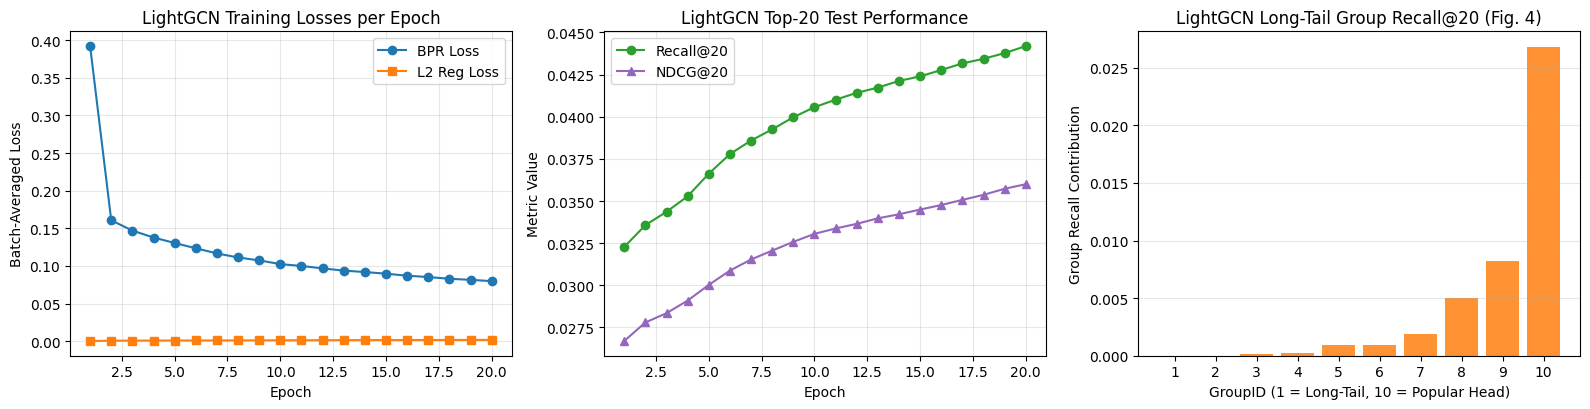

In [5]:
# ==============================================================================
# 5. Hyperparameter Configuration & End-to-End LightGCN Training / Evaluation
# ==============================================================================

@dataclass
class LightGCNConfig:
    # Dataset settings (use 'synthetic' for quick run, or 'yelp2018' / 'amazon-book' / 'ifashion')
    data_dir: str = "./dataset/2018"
    dataset: str = "yelp2018"
    seed: int = 2021

    # LightGCN Model Hyperparameters (matching gusye1234/LightGCN-PyTorch/code/parse.py)
    latent_dim_rec: int = 64        # Embedding dimension d (--recdim=64)
    lightGCN_n_layers: int = 3      # Number of LightGCN layers K (--layer=3)
    decay: float = 1e-4             # L2 regularization weight_decay (--decay=1e-4)
    dropout: int = 0                # Whether to use edge dropout on Graph (0 or 1)
    keep_prob: float = 0.6          # Keep probability when dropout=1 (--keepprob=0.6)
    A_split: bool = False           # Whether to split adjacency matrix into folds
    pretrain: int = 0               # Whether to use pretrained weights
    param_init: str = "normal"      # 'normal' (N(0, 0.1) in LightGCN-PyTorch) or 'xavier_uniform'

    # Optimization & Evaluation settings
    lr: float = 0.001               # Learning rate for Adam optimizer (--lr=0.001)
    batch_size: int = 2048          # Training batch size B (--bpr_batch=2048)
    epochs: int = 30                # Number of training epochs
    verbose: int = 1                # Evaluate every `verbose` epochs
    stop_cnt: int = 10              # Early stopping patience
    top_k: list[int] = field(default_factory=lambda: [20])
    test_batch_size: int = 128
    start_testing_epoch: int = 0

    def to_model_dict(self) -> dict:
        """Converts dataclass to the `config` dict expected by `LightGCN.__init__`."""
        return {
            "latent_dim_rec": self.latent_dim_rec,
            "lightGCN_n_layers": self.lightGCN_n_layers,
            "keep_prob": self.keep_prob,
            "A_split": self.A_split,
            "dropout": self.dropout,
            "pretrain": self.pretrain,
            "param_init": self.param_init,
        }


def run_lightgcn_pipeline(cfg: LightGCNConfig):
    """Runs the complete LightGCN preprocessing, training, evaluation, and plotting pipeline."""
    set_seed(cfg.seed)

    print("=" * 80)
    print("LightGCN: Simplifying and Powering GCN for Recommendation (SIGIR '20)")
    print("=" * 80)
    print(
        f"[Config] dataset={cfg.dataset} | n_layers={cfg.lightGCN_n_layers} | "
        f"latent_dim={cfg.latent_dim_rec} | lr={cfg.lr} | decay={cfg.decay} | "
        f"batch_size={cfg.batch_size} | dropout={cfg.dropout}"
    )
    print(f"[Device] Using {DEVICE}")

    # 1. Load dataset & construct intact normalized graph G (Shared Preprocess Pipeline)
    dataset = SGLDataset(
        data_dir=cfg.data_dir,
        dataset_name=cfg.dataset,
        device=DEVICE,
    )
    print(
        f"[Data]   #Users: {dataset.num_users} | #Items: {dataset.num_items} | "
        f"#Train Interactions: {dataset.num_ratings}"
    )

    data_iter = PairwiseSampler(dataset, batch_size=cfg.batch_size, shuffle=True)
    evaluator = Evaluator(
        user_train_dict=dataset.train_user_dict,
        user_test_dict=dataset.test_user_dict,
        metrics=["Precision", "Recall", "NDCG"],
        top_k=cfg.top_k,
        batch_size=cfg.test_batch_size,
    )

    # 2. Initialize LightGCN model & Adam optimizer (matching utils.BPRLoss in LightGCN-PyTorch)
    model = LightGCN(config=cfg.to_model_dict(), dataset=dataset).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr)

    print("-" * 80)
    print("Metrics:\t" + evaluator.metrics_info())
    print("-" * 80)

    best_epoch = 0
    best_result = np.zeros(3 * len(cfg.top_k), dtype=np.float64)
    best_state_dict = None
    stopping_step = 0

    history = {"epoch": [], "bpr_loss": [], "reg_loss": [], "recall": [], "ndcg": []}

    # 3. Training & Evaluation Loop
    for epoch in range(1, cfg.epochs + 1):
        total_loss, total_bpr_loss, total_reg_loss = 0.0, 0.0, 0.0
        num_batches = 0
        t0 = time()

        model.train()
        for bat_users, bat_pos_items, bat_neg_items in data_iter:
            bat_users = torch.from_numpy(bat_users).long().to(DEVICE)
            bat_pos_items = torch.from_numpy(bat_pos_items).long().to(DEVICE)
            bat_neg_items = torch.from_numpy(bat_neg_items).long().to(DEVICE)

            # BPRLoss.stageOne from gusye1234/LightGCN-PyTorch/code/utils.py
            bpr_l, reg_l = model.bpr_loss(bat_users, bat_pos_items, bat_neg_items)
            weighted_reg_l = reg_l * cfg.decay
            loss = bpr_l + weighted_reg_l

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            total_bpr_loss += bpr_l.item()
            total_reg_loss += weighted_reg_l.item()
            num_batches += 1

        avg_total = total_loss / max(1, num_batches)
        avg_bpr = total_bpr_loss / max(1, num_batches)
        avg_reg = total_reg_loss / max(1, num_batches)

        print(
            f"[iter {epoch:2d} : loss : {avg_total:.4f} = {avg_bpr:.4f} (BPR) + "
            f"{avg_reg:.4f} (Reg), time: {time() - t0:.2f}s]"
        )

        if epoch % cfg.verbose == 0 and epoch > cfg.start_testing_epoch:
            current_result, buf = evaluator.evaluate(model)
            print(f"epoch {epoch:2d}:\t{buf}")

            history["epoch"].append(epoch)
            history["bpr_loss"].append(avg_bpr)
            history["reg_loss"].append(avg_reg)
            history["recall"].append(current_result[1])
            history["ndcg"].append(current_result[2])

            if best_result[1] < current_result[1]:
                best_result = current_result
                best_epoch = epoch
                stopping_step = 0
                best_state_dict = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            else:
                stopping_step += 1
                if stopping_step >= cfg.stop_cnt:
                    print(f"Early stopping triggered at epoch: {epoch}")
                    break

    # 4. Restore best model & compute Long-Tail Group Recall (Section 4.3.1)
    if best_state_dict is not None:
        model.load_state_dict({k: v.to(DEVICE) for k, v in best_state_dict.items()})

    group_recalls = evaluator.evaluate_long_tail_groups(
        model=model,
        train_items=dataset.train_items,
        num_items=dataset.num_items,
        num_groups=10,
        k=cfg.top_k[0],
    )

    print("=" * 80)
    print(f"Best Result @ Epoch {best_epoch}:")
    print("Metrics:\t" + evaluator.metrics_info())
    print("Values: \t" + "\t".join([("%.8f" % x).ljust(12) for x in best_result]))
    print("-" * 80)
    group_str = " | ".join([f"G{g+1}: {val:.4f}" for g, val in enumerate(group_recalls)])
    print(f"Long-Tail Group Recall@{cfg.top_k[0]}: {group_str}")
    print("=" * 80)

    # 5. Plot Training Curves & Long-Tail Group Recall
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

    axes[0].plot(history["epoch"], history["bpr_loss"], marker="o", label="BPR Loss")
    axes[0].plot(history["epoch"], history["reg_loss"], marker="s", label="L2 Reg Loss")
    axes[0].set_title("LightGCN Training Losses per Epoch")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Batch-Averaged Loss")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(history["epoch"], history["recall"], marker="o", color="tab:green", label=f"Recall@{cfg.top_k[0]}")
    axes[1].plot(history["epoch"], history["ndcg"], marker="^", color="tab:purple", label=f"NDCG@{cfg.top_k[0]}")
    axes[1].set_title(f"LightGCN Top-{cfg.top_k[0]} Test Performance")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Metric Value")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    axes[2].bar(np.arange(1, 11), group_recalls, color="tab:orange", alpha=0.85)
    axes[2].set_title(f"LightGCN Long-Tail Group Recall@{cfg.top_k[0]} (Fig. 4)")
    axes[2].set_xlabel("GroupID (1 = Long-Tail, 10 = Popular Head)")
    axes[2].set_ylabel("Group Recall Contribution")
    axes[2].set_xticks(np.arange(1, 11))
    axes[2].grid(True, axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

    return model, history, group_recalls


# Execute the LightGCN pipeline
config = LightGCNConfig(
    latent_dim_rec=64,
    lightGCN_n_layers=3,
    decay=1e-4,
    lr=0.001,
    epochs=20,
)
trained_lgn_model, lgn_history, lgn_long_tail_recalls = run_lightgcn_pipeline(config)

In [7]:
config2 = LightGCNConfig(
    latent_dim_rec=64,
    lightGCN_n_layers=3,
    decay=1e-4,
    lr=0.001,
    epochs=1000,
)
trained_lgn_model2, lgn_history2, lgn_long_tail_recalls2 = run_lightgcn_pipeline(config2)

LightGCN: Simplifying and Powering GCN for Recommendation (SIGIR '20)
[Config] dataset=yelp2018 | n_layers=3 | latent_dim=64 | lr=0.001 | decay=0.0001 | batch_size=2048 | dropout=0
[Device] Using cuda:0
[Data]   #Users: 31668 | #Items: 38048 | #Train Interactions: 1237259
[LightGCN] Initialized embeddings with Normal(0, 0.1).
[LightGCN] Ready (n_layers=3, dropout=0).
--------------------------------------------------------------------------------
Metrics:	Precision@20	Recall@20   	NDCG@20     
--------------------------------------------------------------------------------
[iter  1 : loss : 0.3925 = 0.3922 (BPR) + 0.0003 (Reg), time: 65.55s]
epoch  1:	0.01540830  	0.03227410  	0.02669312  
[iter  2 : loss : 0.1613 = 0.1607 (BPR) + 0.0007 (Reg), time: 66.19s]
epoch  2:	0.01587723  	0.03356591  	0.02779168  
[iter  3 : loss : 0.1478 = 0.1470 (BPR) + 0.0008 (Reg), time: 66.75s]
epoch  3:	0.01617090  	0.03435931  	0.02834295  
[iter  4 : loss : 0.1387 = 0.1378 (BPR) + 0.0009 (Reg), time: 6

: 